# Coded gamma camera: from an energy shadow to a source image


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`detector_energy`，shape `(1, 256, 256)`，dtype `<u4`：Full measured integrated deposited energy, keV; batch, detector row, detector column.；`mask_pattern`，shape `(1, 124, 124)`，dtype `<f4`：Binary dimensionless aperture transmission; 1 is an opening, 0 tungsten; batch, mask row, mask column.。未知量为50mm源平面的126×126带符号伽马源响应图。

获取模型：已知几何放大掩模阴影与源强度卷积产生累计探测能量，叠加背景和误差。

如何恢复：src.solvers.reconstruct：坏点/平滑处理、MURA解码循环卷积；accorsi为比较。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3原探测能量；5掩模几何；7主动恢复；9 MURA/Accorsi；11距离敏感性；13坏点/平滑消融。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留6个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。输出是带符号解码响应，不是已校准非负真实放射浓度。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

A tungsten aperture multiplexes photons from a radioactive source onto a semiconductor detector. This review reconstructs the **bound real 15-minute Am-241 exposure**, using the published planar MURA decoding stage at the known 50 mm plane. The active computation uses only cleaned local modules. An independently captured run of the unchanged authors' code provides a method comparison; it is not physical ground truth. Absolute activity in Bq cannot be inferred without an independent sensitivity calibration.

The scientific questions are: does local extraction preserve the original camera and decoder conventions, how do alternative decoder sampling and defective-pixel correction change the image, and how sensitive is the result to the assumed source plane? This notebook is a selected-stage experiment, not a claim to reproduce the paper's later 3D localization fits or optional 3D-MLEM solver.

In [1]:
import os,sys,time,json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').exists():root=root.parent
sys.path.insert(0,str(root))
from src.preprocessing import load_data,preprocess
from src.physics_model import decoding_pattern,nearest_resize,projected_size,central_crop,source_coordinates,cyclic_convolve
from src.solvers import reconstruct,accorsi
from src.visualization import image_panels,metrics,contrast_to_noise
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,'figure.dpi':110,'savefig.dpi':180})
raw,mask=load_data(root/'data/raw_data.npz')
original=np.load(root/'notebooks/reference_outputs/upstream.npz',allow_pickle=False)
print('Bound observations:',raw.shape,raw.dtype,'keV; binary mask:',mask.shape,mask.dtype)
print('Actual kernel executable:',sys.executable,'; NumPy',np.__version__)
print('No independently measured source image is available.')

Bound observations: (256, 256) uint32 keV; binary mask: (124, 124) float32
Actual kernel executable: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe ; NumPy 2.4.6
No independently measured source image is available.


## 2. Data

Every native detector sample is retained. The uint32 image stores accumulated deposited energy in keV, not a rendered photograph and not a Poisson photon-count histogram. Consequently, this review does not invent a Poisson count uncertainty from keV values. Bright/defective pixels can contribute much more than the modulated aperture shadow. The prescribed robust correction replaces strict 1st/99th percentile outliers by the local 3 by 3 median, followed by reflected Gaussian smoothing with sigma one detector pixel. The signed correction image below identifies exactly which spatial structure changes; no hidden clean image is substituted.

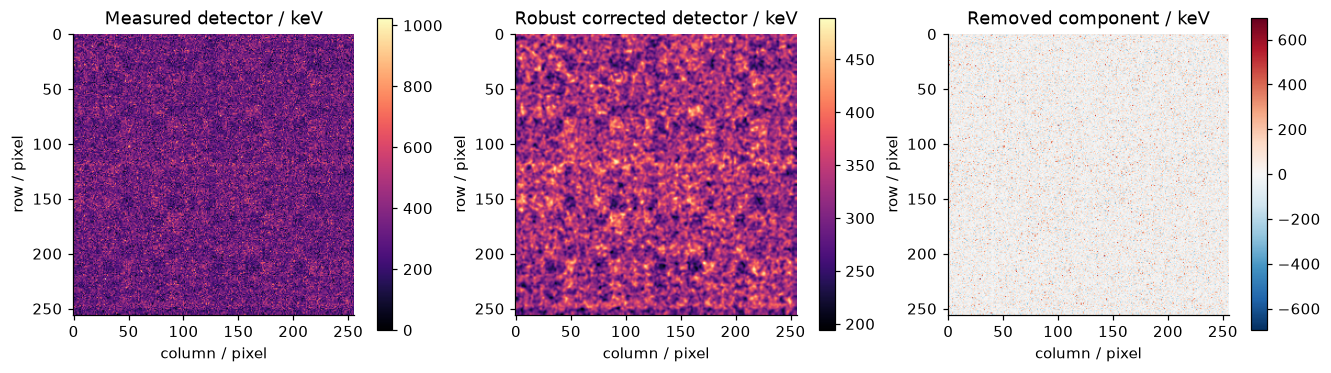

Detector native range 0 1024 keV; corrected range 194.1808624267578 489.03131103515625 keV


In [2]:
clean=preprocess(raw)
fig_data=image_panels([raw,clean,raw.astype(float)-clean],['Measured detector / keV','Robust corrected detector / keV','Removed component / keV'])
signed=fig_data.axes[2].images[0];limit=float(np.max(np.abs(raw.astype(float)-clean)));signed.set_cmap('RdBu_r');signed.set_clim(-limit,limit)
plt.show()
print('Detector native range',int(raw.min()),int(raw.max()),'keV; corrected range',float(clean.min()),float(clean.max()),'keV')

## 3. Physics

For source-plane distance $z$, camera gap $b$ and source displacement $x$, the shadow is displaced by $-bx/z$, while the projected mask is magnified by $m=1+b/z$. Here $b=20$ mm and $z=50$ mm. The detector pitch $p=0.055$ mm therefore corresponds to a source-plane pitch $pz/b=0.1375$ mm.

With $f$ the source image, $h$ the projected mask response, $\beta$ the unmodulated background and $\epsilon$ the measurement error, the nominal sampled model is

$$y_{ij}=\sum_{kl}h_{i-k,j-l}(z)f_{kl}+\beta_{ij}+\epsilon_{ij}.$$

The repeated mask supports a central-period circular approximation. The signed decoder assigns opposite signs to closed and open logical mask cells while retaining the zero-filling NTHT rows/columns. Its spatial sampling and orientation are consequential: FFT signs, half-pixel resizing and decoder central-pixel treatment can shift or change the reconstructed response. The supplied mask is independent instrument calibration. Finite apertures, mask penetration and camera alignment are systematic departures from the simplified periodic model.

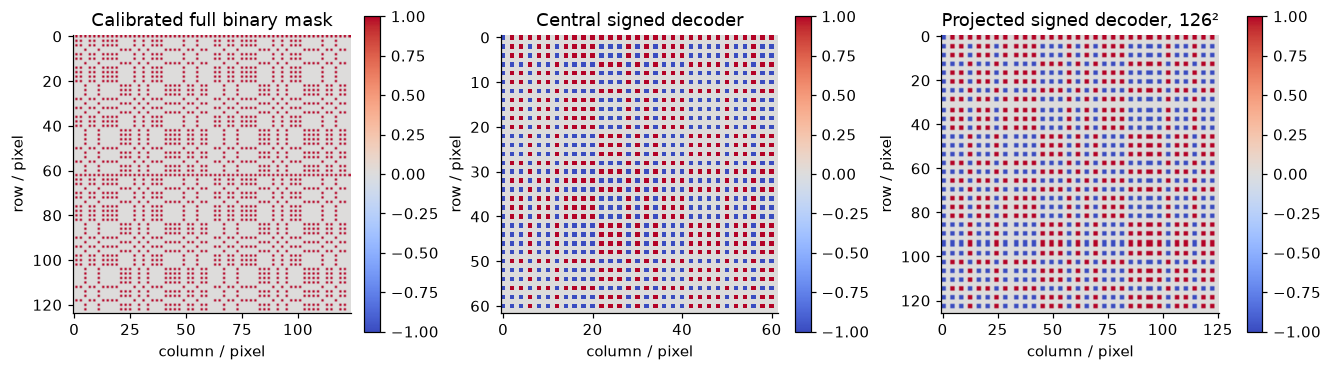

Magnification: 1.4 ; projected central period: 126 detector pixels
Direct-sum vs FFT convolution maximum absolute difference: 7.105427357601002e-15


In [3]:
decoder=decoding_pattern(mask);projected=nearest_resize(decoder,projected_size())
fig_mask=image_panels([mask,decoder,projected],['Calibrated full binary mask','Central signed decoder','Projected signed decoder, 126²'],cmap='coolwarm',symmetric=True)
plt.show()
print('Magnification:',1+20/50,'; projected central period:',projected_size(),'detector pixels')
# Independent direct-sum operator verification, distinct from the inverse decoder.
x=np.arange(20,dtype=float).reshape(4,5);h=np.sin(x)
direct=sum(x[i,j]*np.roll(h,(i,j),(0,1)) for i in range(4) for j in range(5))
print('Direct-sum vs FFT convolution maximum absolute difference:',np.max(np.abs(direct-cyclic_convolve(x,h))))

## 4. Method

After robust detector correction, the direct MURA image is

$$r=\operatorname{Re}\mathcal F^{-1}\left[\mathcal F(c)\mathcal F(d)\right],$$

where $c$ is the central detector crop, $d$ is the signed decoder projected by nearest-neighbour centre sampling, and $\mathcal F$ is the discrete Fourier transform with backward inverse normalization. This computes a circular **sum**, so the response remains unnormalized in summed keV units. Negative sidelobes and the original orientation are retained. There is no optimization initialization, trained weight, convergence tolerance or artificial iterative loop.

Accorsi sparse decoding is reconstructed independently as an active comparison: zero-insert the decoder with the rounded aperture magnification and sample the detector on the corresponding interpolation grid before convolution. Its 124² grid differs from MURA's 126² grid at this plane. Raw peak amplitudes are consequently not treated as equivalent absolute activities. Only each method's own original run supplies its parity comparison.

{
  "fresh_MURA_seconds": 0.007038700001430698,
  "fresh_Accorsi_seconds": 0.007879600001615472,
  "metrics": {
    "MURA fresh vs original": {
      "ncc": 1.0000000000000002,
      "nrmse": 0.0
    },
    "Accorsi fresh vs original": {
      "ncc": 0.9999999999972264,
      "nrmse": 1.2856621447527002e-07
    }
  }
}


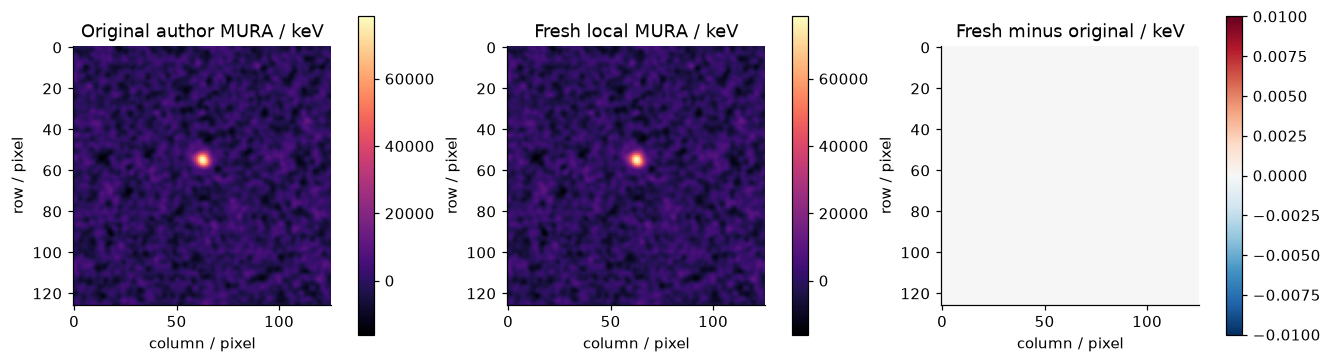

In [4]:
started=time.perf_counter()
fresh=reconstruct(raw,mask)
fresh_seconds=time.perf_counter()-started
started=time.perf_counter();fresh_accorsi=accorsi(raw,mask);accorsi_seconds=time.perf_counter()-started
np.savez_compressed(root/'output/reconstruction.npz',reconstruction=fresh[None])
method_metrics={'MURA fresh vs original':metrics(fresh,original['mura']),'Accorsi fresh vs original':metrics(fresh_accorsi,original['accorsi'])}
print(json.dumps({'fresh_MURA_seconds':fresh_seconds,'fresh_Accorsi_seconds':accorsi_seconds,'metrics':method_metrics},indent=2))
fig_parity=image_panels([original['mura'],fresh,fresh-original['mura']],['Original author MURA / keV','Fresh local MURA / keV','Fresh minus original / keV'])
signed=fig_parity.axes[2].images[0];limit=max(float(np.max(np.abs(fresh-original['mura']))),.01);signed.set_cmap('RdBu_r');signed.set_clim(-limit,limit)
plt.show()

## 5. Results and controlled experiments

The first comparison distinguishes the independent original measurements from the newly computed local results. NCC is uncentered cosine similarity; NRMSE uses the reference dynamic range. These metrics test extraction fidelity, not independently known physical accuracy. No normalization, alignment or crop is fitted to improve them.

Below, both decoder methods are actually computed. For shape visualization only, the centre-column profiles are divided by each profile's own absolute maximum; the machine-readable response images and all submitted values retain their original energy scale. The diagnostic contrast-to-noise value is the 3 by 3 peak-neighbourhood mean relative to pixels outside its 11 by 11 exclusion square, divided by the background standard deviation. It is not the paper's fitted ROI localization metric.

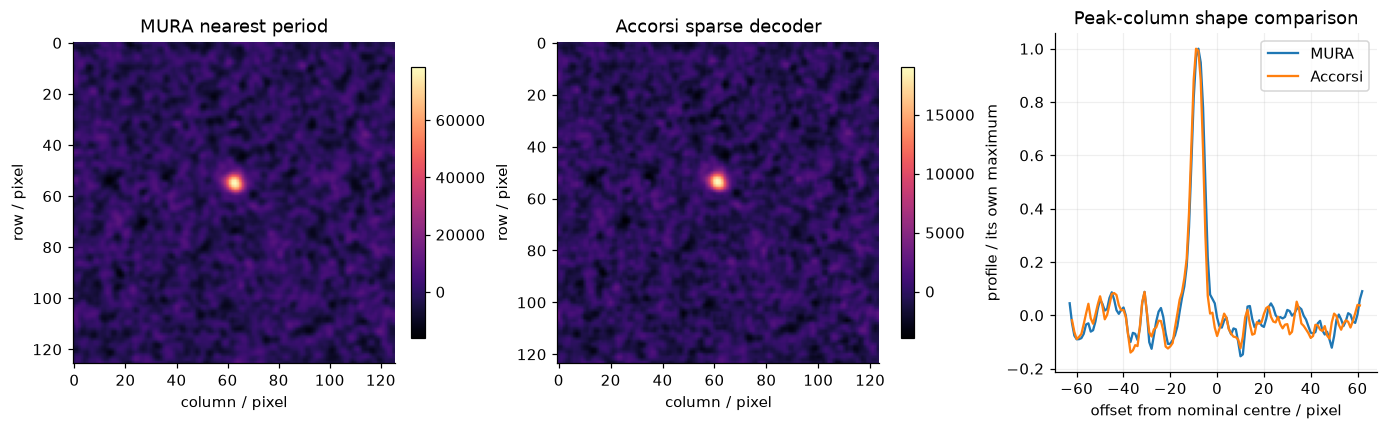

Diagnostic contrast-to-noise: {
  "MURA": 19.352489471435547,
  "Accorsi": 18.67340850830078
}


In [5]:
fig_methods,axs=plt.subplots(1,3,figsize=(12.5,3.8),layout='constrained')
for ax,a,name in zip(axs[:2],[fresh,fresh_accorsi],['MURA nearest period','Accorsi sparse decoder']):
 im=ax.imshow(a,cmap='magma');ax.set(title=name,xlabel='column / pixel',ylabel='row / pixel');fig_methods.colorbar(im,ax=ax,shrink=.8)
for a,name in [(fresh,'MURA'),(fresh_accorsi,'Accorsi')]:
 col=np.unravel_index(np.argmax(a),a.shape)[1];v=a[:,col].astype(float);axs[2].plot(np.arange(len(v))-len(v)/2,v/np.max(np.abs(v)),label=name)
axs[2].set(title='Peak-column shape comparison',xlabel='offset from nominal centre / pixel',ylabel='profile / its own maximum');axs[2].legend();axs[2].grid(alpha=.2)
plt.show()
cnr={'MURA':contrast_to_noise(fresh),'Accorsi':contrast_to_noise(fresh_accorsi)}
print('Diagnostic contrast-to-noise:',json.dumps(cnr,indent=2))

### Assumed-plane sensitivity

The same measured detector exposure is reconstructed on multiple alternative planes. Each plane has its own projected sampling, so the displayed grid sizes change honestly rather than silently resizing the science arrays. This measures geometric sensitivity of the selected decoding method; it does not constitute 3D-MLEM or prove a depth estimate. The nominal 50 mm condition is used for the submitted map. Camera assembly and tilt uncertainties can displace the lateral response even when the algorithm matches its original implementation.

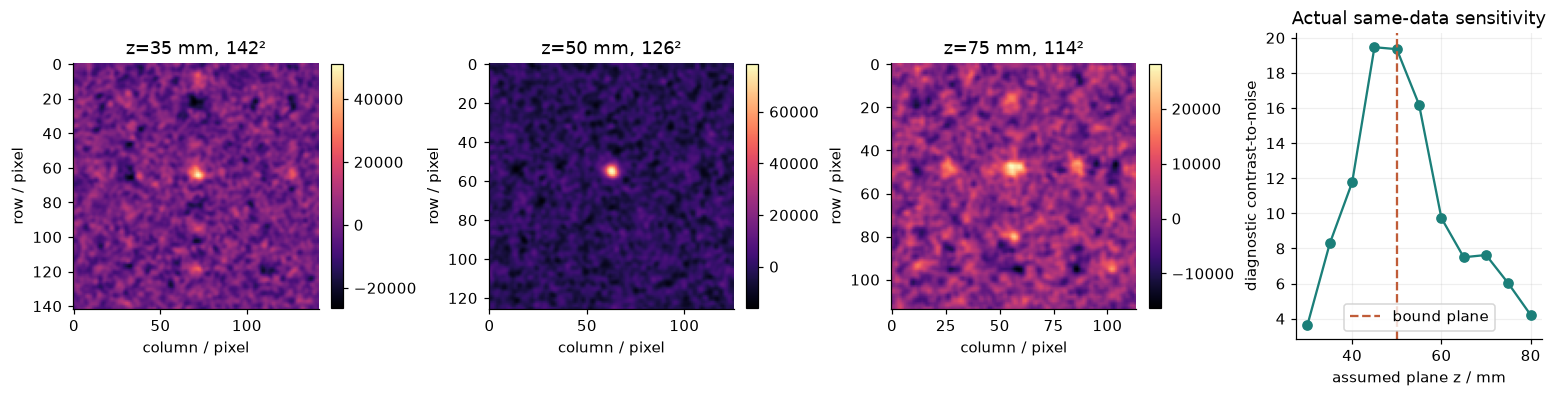

In [6]:
distances=np.arange(30.,81.,5.)
sweep=[reconstruct(raw,mask,distance=float(z)) for z in distances]
sweep_cnr=np.array([contrast_to_noise(a) for a in sweep])
sweep_peak=np.array([np.unravel_index(np.argmax(a),a.shape) for a in sweep])
fig_geometry,axes=plt.subplots(1,4,figsize=(14,3.5),layout='constrained')
for ax,z in zip(axes[:3],[35.,50.,75.]):
 a=sweep[list(distances).index(z)];im=ax.imshow(a,cmap='magma');ax.set(title=f'z={z:g} mm, {a.shape[0]}²',xlabel='column / pixel',ylabel='row / pixel');fig_geometry.colorbar(im,ax=ax,shrink=.8)
axes[3].plot(distances,sweep_cnr,'o-',color='#1b7f79');axes[3].axvline(50,color='#c05c38',ls='--',label='bound plane');axes[3].set(xlabel='assumed plane z / mm',ylabel='diagnostic contrast-to-noise',title='Actual same-data sensitivity');axes[3].legend();axes[3].grid(alpha=.2)
plt.show()

### Defective-pixel and smoothing ablations

These controlled experiments vary one preprocessing component at a time on the **same bound raw energy image**. The raw and median-only paths are actually decoded; they are not zero placeholders. Differences reflect both noise amplification and the blur/resolution tradeoff, so a higher peak or diagnostic contrast alone is not evidence of a more accurate physical scene. Spatial sharpness and sidelobes must be inspected together.

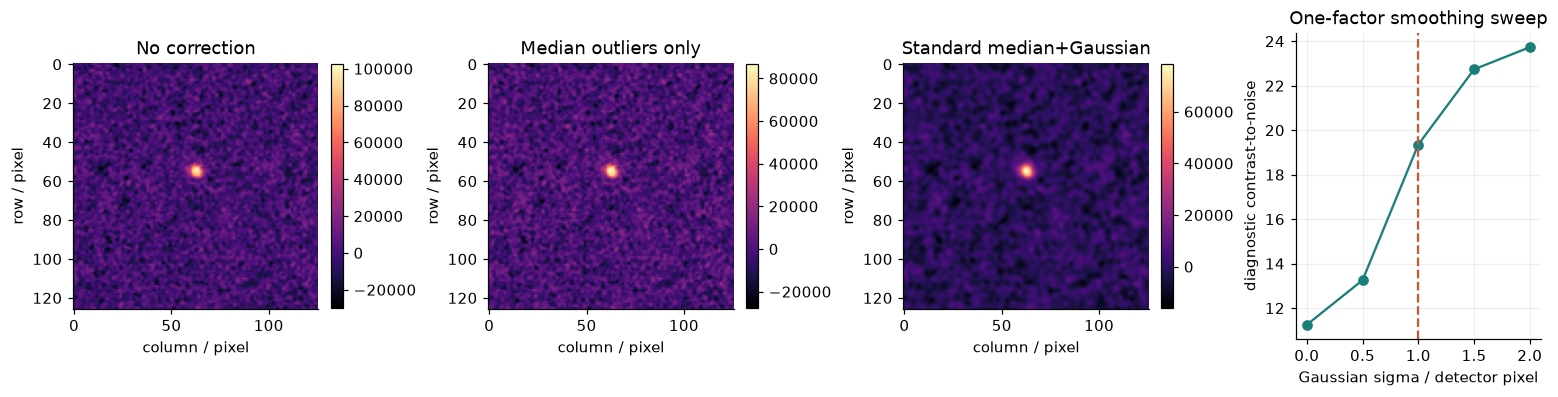

Preprocessing ablation metrics relative to standard, not truth:
{
  "No correction": {
    "ncc": 0.8323094596295938,
    "nrmse": 0.0552838870430594
  },
  "Median outliers only": {
    "ncc": 0.8573161284605857,
    "nrmse": 0.046876962944296365
  },
  "Standard median+Gaussian": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  }
}


In [7]:
variants={'No correction':reconstruct(raw,mask,sigma=0,reject_outliers=False),'Median outliers only':reconstruct(raw,mask,sigma=0),'Standard median+Gaussian':fresh}
sigmas=np.array([0.,.5,1.,1.5,2.]);smooth=[reconstruct(raw,mask,sigma=float(s)) for s in sigmas]
fig_ablation,axes=plt.subplots(1,4,figsize=(14,3.5),layout='constrained')
for ax,(name,a) in zip(axes[:3],variants.items()):
 im=ax.imshow(a,cmap='magma');ax.set(title=name,xlabel='column / pixel',ylabel='row / pixel');fig_ablation.colorbar(im,ax=ax,shrink=.8)
axes[3].plot(sigmas,[contrast_to_noise(a) for a in smooth],'o-',color='#1b7f79');axes[3].set(xlabel='Gaussian sigma / detector pixel',ylabel='diagnostic contrast-to-noise',title='One-factor smoothing sweep');axes[3].axvline(1,color='#c05c38',ls='--');axes[3].grid(alpha=.2)
plt.show()
print('Preprocessing ablation metrics relative to standard, not truth:')
print(json.dumps({k:metrics(a,fresh) for k,a in variants.items()},indent=2))

## 6. Conclusion

The fresh local reconstruction reproduces the independently executed original planar MURA and Accorsi stages on exactly the bundled experimental observation. The figures expose the coded detector shadow, defective-pixel correction, signed aperture construction, method-specific sampling, residual extraction error and measured-data sensitivity to geometry and smoothing. The selected task is an image reconstruction, rather than a fit to a hidden source coordinate.

The map remains a resolution-limited signed decoding response. Its agreement with a method reference does not establish absolute activity or exact physical source shape. Finite geometry, penetrating radiation, detector errors and alignment systematics remain scientific limitations. The independently checked periodic forward primitive and adjoint validate numerical conventions; they do not erase those acquisition limitations.

In [8]:
# Keep separately identified fresh numerical measurements; figures/source exports are maintainer-only.
import importlib.util
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert exitcode==0
private=os.environ.get('IMAGING101_GAMMA_EXPORT')
if private:
 export=Path(private);export.mkdir(parents=True,exist_ok=True)
 for i,fig in enumerate([fig_data,fig_mask,fig_parity,fig_methods,fig_geometry,fig_ablation],1):
  for ext in ['png','svg','pdf']:fig.savefig(export/f'gamma-{i}.{ext}',bbox_inches='tight')
 source={'fresh_mura':fresh,'fresh_accorsi':fresh_accorsi,'distances_mm':distances,'sweep_cnr':sweep_cnr,'sweep_peak_indices':sweep_peak,'sigmas_pixel':sigmas,'smoothing_cnr':np.array([contrast_to_noise(a) for a in smooth])}
 source.update({f'plane_{int(z)}mm':a for z,a in zip(distances,sweep)})
 source.update({f'preprocess_{i}':a for i,a in enumerate(variants.values())})
 source.update({f'sigma_{s:g}':a for s,a in zip(sigmas,smooth)})
 np.savez_compressed(export.parent/'gamma_experiments.npz',**source)
 (export.parent/'gamma_experiments.json').write_text(json.dumps({'method_metrics':method_metrics,'fresh_MURA_seconds':fresh_seconds,'fresh_Accorsi_seconds':accorsi_seconds,'cnr':cnr,'judge':report},indent=2),encoding='utf8')
plt.close('all')

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  "thresholds": {
    "ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "nrmse": {
      "comparison": "<=",
      "boundary": 5e-06
    }
  },
  "errors": []
}
